In [1]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../data/raw")

train_path = DATA_DIR / "ir_train.csv"

df = pd.read_csv(train_path)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (1500000, 45)

Columns:
['journey_id', 'train_number', 'train_type', 'departure_date', 'year', 'month', 'day_of_week', 'departure_hour', 'is_weekend', 'is_night_departure', 'is_peak_hour', 'is_festival_season', 'season', 'zone', 'zone_abbr', 'source_station_category', 'destination_station_category', 'distance_km', 'num_scheduled_stops', 'scheduled_travel_hours', 'track_doubled', 'is_hdn_route', 'traction_type', 'is_electrified', 'psr_count', 'is_circular_route', 'is_monsoon_season', 'is_fog_risk', 'fog_risk_score', 'zone_fog_index', 'zone_congestion_index', 'season_severity_score', 'loco_age_years', 'coach_age_years', 'has_lhb_coaches', 'is_rake_shared', 'maintenance_score', 'seat_utilisation_pct', 'is_overloaded', 'late_incoming_rake', 'is_special_train', 'route_historical_ontime_pct', 'primary_delay_cause', 'delay_minutes', 'is_delayed']


In [2]:
df.head()

,journey_id,train_number,train_type,departure_date,year,month,day_of_week,departure_hour,is_weekend,is_night_departure,...,is_rake_shared,maintenance_score,seat_utilisation_pct,is_overloaded,late_incoming_rake,is_special_train,route_historical_ontime_pct,primary_delay_cause,delay_minutes,is_delayed
0,IR01717809,12536,Superfast Express,2023-09-18,2023,9,0,7,0,0,...,1,5.5,88.8,0,0,0,67.8,Flooding / Waterlogging,110,1
1,IR00931776,12806,Superfast Express,2020-04-09,2020,4,3,8,0,0,...,1,6.6,83.6,0,0,0,57.0,On Time,3,0
2,IR00096904,22416,Vande Bharat Express,2024-12-13,2024,12,4,18,0,0,...,0,4.1,81.6,0,0,0,81.8,On Time,5,0
3,IR00047736,12250,Garib Rath Express,2018-11-29,2018,11,3,18,0,0,...,0,5.5,82.1,0,1,0,52.3,Track Congestion,135,1
4,IR00726037,74588,DEMU/MEMU,2020-06-18,2020,6,3,5,0,0,...,1,8.0,58.3,0,1,0,64.3,Track Congestion,154,1


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500000 entries, 0 to 1499999
Data columns (total 45 columns):
 #   Column                        Non-Null Count    Dtype  
---  ------                        --------------    -----  
 0   journey_id                    1500000 non-null  object 
 1   train_number                  1500000 non-null  int64  
 2   train_type                    1500000 non-null  object 
 3   departure_date                1500000 non-null  object 
 4   year                          1500000 non-null  int64  
 5   month                         1500000 non-null  int64  
 6   day_of_week                   1500000 non-null  int64  
 7   departure_hour                1500000 non-null  int64  
 8   is_weekend                    1500000 non-null  int64  
 9   is_night_departure            1500000 non-null  int64  
 10  is_peak_hour                  1500000 non-null  int64  
 11  is_festival_season            1500000 non-null  int64  
 12  season                      

In [4]:
df.isnull().sum().sort_values(ascending=False).head(20)

journey_id                      0
train_number                    0
train_type                      0
departure_date                  0
year                            0
month                           0
day_of_week                     0
departure_hour                  0
is_weekend                      0
is_night_departure              0
is_peak_hour                    0
is_festival_season              0
season                          0
zone                            0
zone_abbr                       0
source_station_category         0
destination_station_category    0
distance_km                     0
num_scheduled_stops             0
scheduled_travel_hours          0
dtype: int64

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
journey_id,1500000,1500000,IR00641274,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
train_number,1500000.0,NaN,NaN,NaN,23665.976935,21036.932793,11100.0,11900.0,12647.0,22221.0,82998.0
train_type,1500000,15,Mail/Express,421047,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departure_date,1500000,2556,2018-08-02,688,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,1500000.0,NaN,NaN,NaN,2021.002774,2.000014,2018.0,2019.0,2021.0,2023.0,2024.0
month,1500000.0,NaN,NaN,NaN,6.517572,3.448396,1.0,4.0,7.0,10.0,12.0
day_of_week,1500000.0,NaN,NaN,NaN,3.000643,2.001999,0.0,1.0,3.0,5.0,6.0
departure_hour,1500000.0,NaN,NaN,NaN,13.112735,5.832482,0.0,8.0,14.0,18.0,23.0
is_weekend,1500000.0,NaN,NaN,NaN,0.286304,0.452033,0.0,0.0,0.0,1.0,1.0
is_night_departure,1500000.0,NaN,NaN,NaN,0.100677,0.3009,0.0,0.0,0.0,0.0,1.0


In [6]:
dictionary = pd.read_csv(
    DATA_DIR / "ir_data_dictionary.csv"
)

dictionary

,column,type,description
0,journey_id,string,Unique journey ID (IR + 8 digits)
1,train_number,string,5-digit IR train number
2,train_type,category,"Type of train (Vande Bharat, Rajdhani, Mail, P..."
3,departure_date,date,Scheduled departure date (YYYY-MM-DD)
4,year,int,Year (2018–2024)
5,month,int,Month (1–12)
6,day_of_week,int,"Day of week (0=Monday, 6=Sunday)"
7,departure_hour,int,Scheduled departure hour (0–23)
8,is_weekend,binary,1 if Saturday or Sunday
9,is_night_departure,binary,1 if departure between 10pm and 4am


In [7]:
dictionary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   column       45 non-null     object
 1   type         45 non-null     object
 2   description  45 non-null     object
dtypes: object(3)
memory usage: 1.2+ KB


In [8]:
# KALANTAR: Initial data quality audit

print("Dataset shape:", df.shape)

print("\nColumn data types:")
print(df.dtypes.value_counts())

print("\nMissing values — top 20:")
missing = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

print(missing.head(20))

print("\nTotal missing cells:", int(df.isnull().sum().sum()))

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nUnique journey IDs:", df["journey_id"].nunique())

print(
    "Duplicate journey IDs:",
    df["journey_id"].duplicated().sum()
)

Dataset shape: (1500000, 45)

Column data types:
int64      25
object     10
float64    10
Name: count, dtype: int64

Missing values — top 20:
journey_id                      0
train_number                    0
train_type                      0
departure_date                  0
year                            0
month                           0
day_of_week                     0
departure_hour                  0
is_weekend                      0
is_night_departure              0
is_peak_hour                    0
is_festival_season              0
season                          0
zone                            0
zone_abbr                       0
source_station_category         0
destination_station_category    0
distance_km                     0
num_scheduled_stops             0
scheduled_travel_hours          0
dtype: int64

Total missing cells: 0

Exact duplicate rows: 0

Unique journey IDs: 1500000
Duplicate journey IDs: 0


In [9]:
print("Delay statistics (minutes):")
print(df["delay_minutes"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

print("\nDelay target distribution:")
print(df["is_delayed"].value_counts(dropna=False))

print("\nDelay target proportions:")
print(
    df["is_delayed"]
      .value_counts(normalize=True, dropna=False)
      .round(4)
)

print("\nSample target records:")
print(
    df[
        [
            "journey_id",
            "delay_minutes",
            "is_delayed",
            "primary_delay_cause"
        ]
    ].head(10)
)

Delay statistics (minutes):
count    1.500000e+06
mean     9.772833e+01
std      6.617405e+01
min      0.000000e+00
25%      1.300000e+01
50%      1.110000e+02
75%      1.400000e+02
90%      1.730000e+02
95%      1.970000e+02
99%      2.540000e+02
max      5.790000e+02
Name: delay_minutes, dtype: float64

Delay target distribution:
is_delayed
1    1078329
0     421671
Name: count, dtype: int64

Delay target proportions:
is_delayed
1    0.7189
0    0.2811
Name: proportion, dtype: float64

Sample target records:
   journey_id  delay_minutes  is_delayed      primary_delay_cause
0  IR01717809            110           1  Flooding / Waterlogging
1  IR00931776              3           0                  On Time
2  IR00096904              5           0                  On Time
3  IR00047736            135           1         Track Congestion
4  IR00726037            154           1         Track Congestion
5  IR01774740              0           0                  On Time
6  IR01270166         

In [12]:
# Test both possible threshold conventions.
# The dictionary says "more than 15 minutes",
# which normally means strictly greater than 15.

expected_target = (df["delay_minutes"] > 15).astype("int8")

comparison = pd.crosstab(
    expected_target,
    df["is_delayed"],
    rownames=["Derived from delay_minutes"],
    colnames=["Provided is_delayed"],
    dropna=False
)

print(comparison)

mismatch_count = (
    expected_target != df["is_delayed"]
).sum()

print("\nTarget mismatches:", mismatch_count)

Provided is_delayed              0        1
Derived from delay_minutes                 
0                           421671        0
1                                0  1078329

Target mismatches: 0


In [13]:
important_columns = [
    "train_number",
    "train_type",
    "departure_date",
    "departure_hour",
    "distance_km",
    "num_scheduled_stops",
    "scheduled_travel_hours",
    "zone_congestion_index",
    "fog_risk_score",
    "maintenance_score",
    "late_incoming_rake",
    "route_historical_ontime_pct",
    "primary_delay_cause",
    "delay_minutes",
    "is_delayed",
]

print(
    dictionary[
        dictionary["column"].isin(important_columns)
    ].to_string(index=False)
)

                     column     type                                                            description
               train_number   string                                                5-digit IR train number
                 train_type category          Type of train (Vande Bharat, Rajdhani, Mail, Passenger, etc.)
             departure_date     date                                  Scheduled departure date (YYYY-MM-DD)
             departure_hour      int                                        Scheduled departure hour (0–23)
                distance_km      int                                     Total route distance in kilometres
        num_scheduled_stops      int                                 Number of intermediate scheduled halts
     scheduled_travel_hours    float                              Scheduled end-to-end travel time in hours
             fog_risk_score    float         Continuous fog risk score (0–1) based on month, hour, and zone
      zone_congestion_index 

In [14]:
# KALANTAR: Full dataset validation

print("Total missing cells:", df.isnull().sum().sum())

print("\nColumns containing missing values:")
print(df.columns[df.isnull().any()].tolist())

print("\nNegative delays:", (df["delay_minutes"] < 0).sum())

print("Zero-delay journeys:", (df["delay_minutes"] == 0).sum())

print("Delays over 3 hours:", (df["delay_minutes"] > 180).sum())

print("Delays over 6 hours:", (df["delay_minutes"] > 360).sum())

print("\nUnique delay values:", df["delay_minutes"].nunique())

Total missing cells: 0

Columns containing missing values:
[]

Negative delays: 0
Zero-delay journeys: 28003
Delays over 3 hours: 119625
Delays over 6 hours: 755

Unique delay values: 466


In [15]:
df["departure_date"] = pd.to_datetime(
    df["departure_date"],
    errors="coerce"
)

print("Invalid dates:", df["departure_date"].isna().sum())

print("Earliest departure:", df["departure_date"].min())

print("Latest departure:", df["departure_date"].max())

print("\nRecords per year:")
print(df["departure_date"].dt.year.value_counts().sort_index())

print("\nStored year vs date year mismatches:")
print(
    (df["year"] != df["departure_date"].dt.year).sum()
)

Invalid dates: 0
Earliest departure: 2018-01-01 00:00:00
Latest departure: 2024-12-30 00:00:00

Records per year:
departure_date
2018    213861
2019    214095
2020    214236
2021    213670
2022    214353
2023    215538
2024    214247
Name: count, dtype: int64

Stored year vs date year mismatches:
0


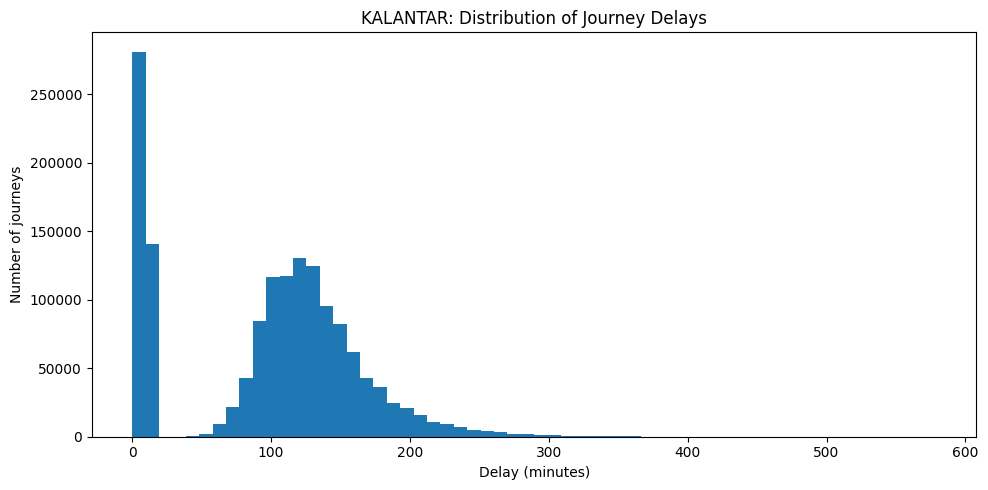

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df["delay_minutes"],
    bins=60
)

plt.title("KALANTAR: Distribution of Journey Delays")
plt.xlabel("Delay (minutes)")
plt.ylabel("Number of journeys")
plt.tight_layout()
plt.show()

In [18]:
print(
    df.groupby(df["departure_date"].dt.year)["delay_minutes"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)

                 count   mean  median  min  max
departure_date                                 
2018            213861  97.66   111.0    0  524
2019            214095  97.94   111.0    0  501
2020            214236  97.59   111.0    0  567
2021            213670  97.54   110.0    0  483
2022            214353  97.86   111.0    0  579
2023            215538  97.80   110.0    0  559
2024            214247  97.70   111.0    0  522


In [19]:
print(
    df["primary_delay_cause"]
      .value_counts(dropna=False)
      .head(20)
)

print("\nMean delay by recorded cause:")

print(
    df.groupby("primary_delay_cause")["delay_minutes"]
      .agg(["count", "mean", "median"])
      .sort_values("count", ascending=False)
      .head(20)
      .round(2)
)

primary_delay_cause
On Time                    421671
Track Congestion           241693
Flooding / Waterlogging    208900
Late Incoming Rake         162183
Track Maintenance / PSR    139761
Station Congestion          71834
Signal Failure              40735
Level Crossing Delay        31456
Passenger Emergency         31352
Freight Priority            31240
Unscheduled Halt            31208
Crew Availability           31088
Loco / Engine Failure       24737
Fog / Low Visibility        20981
Technical Inspection        11161
Name: count, dtype: int64

Mean delay by recorded cause:
                          count    mean  median
primary_delay_cause                            
On Time                  421671    7.00     7.0
Track Congestion         241693  134.70   128.0
Flooding / Waterlogging  208900  135.81   129.0
Late Incoming Rake       162183  144.95   137.0
Track Maintenance / PSR  139761  136.01   129.0
Station Congestion        71834  133.79   127.0
Signal Failure            407

In [20]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Work on a separate modelling copy.
# Keep the raw source file unchanged.
model_df = df.copy()

model_df["departure_date"] = pd.to_datetime(
    model_df["departure_date"],
    errors="coerce"
)

# Sort chronologically
model_df = model_df.sort_values("departure_date").reset_index(drop=True)

# Chronological split
train_df = model_df[
    model_df["departure_date"].dt.year <= 2022
].copy()

val_df = model_df[
    model_df["departure_date"].dt.year == 2023
].copy()

test_df = model_df[
    model_df["departure_date"].dt.year == 2024
].copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

print("\nDate ranges:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        name,
        part["departure_date"].min(),
        "to",
        part["departure_date"].max()
    )

print("\nMean delay by split:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        name,
        "mean =", round(part["delay_minutes"].mean(), 2),
        "| median =", round(part["delay_minutes"].median(), 2)
    )

Training rows: 1070215
Validation rows: 215538
Test rows: 214247

Date ranges:
Train 2018-01-01 00:00:00 to 2022-12-31 00:00:00
Validation 2023-01-01 00:00:00 to 2023-12-31 00:00:00
Test 2024-01-01 00:00:00 to 2024-12-30 00:00:00

Mean delay by split:
Train mean = 97.72 | median = 111.0
Validation mean = 97.8 | median = 110.0
Test mean = 97.7 | median = 111.0


In [21]:
# Learn the baseline using training data only
baseline_prediction = train_df["delay_minutes"].median()

# Evaluate on validation and final test sets
for name, part in [
    ("Validation", val_df),
    ("Final test", test_df),
]:
    actual = part["delay_minutes"]
    predicted = np.full(len(part), baseline_prediction)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    print(f"\n{name} results")
    print("Baseline prediction:", baseline_prediction, "minutes")
    print("MAE:", round(mae, 2), "minutes")
    print("RMSE:", round(rmse, 2), "minutes")


Validation results
Baseline prediction: 111.0 minutes
MAE: 52.67 minutes
RMSE: 67.68 minutes

Final test results
Baseline prediction: 111.0 minutes
MAE: 52.4 minutes
RMSE: 67.43 minutes


In [22]:
from pathlib import Path

Path("../docs").mkdir(parents=True, exist_ok=True)

report = f"""
KALANTAR — Experiment 001
Target: delay_minutes
Split: chronological by departure year

Training rows: {len(train_df)}
Validation rows: {len(val_df)}
Test rows: {len(test_df)}

Baseline: training-set median
Baseline prediction: {baseline_prediction} minutes
"""

Path("../docs/experiment_001.txt").write_text(
    report,
    encoding="utf-8"
)

print(report)
print("Saved to ../docs/experiment_001.txt")


KALANTAR — Experiment 001
Target: delay_minutes
Split: chronological by departure year

Training rows: 1070215
Validation rows: 215538
Test rows: 214247

Baseline: training-set median
Baseline prediction: 111.0 minutes

Saved to ../docs/experiment_001.txt
